# Meu Ciclo+ | Data Science — Entrega 4
## Viabilidade, modelagem e indicador agregado sobre a série SINAN/DATASUS

**Líder da etapa:** Matheus Albertini, com Abel e Lucca. **Continuação de:** `01_eda_sinan_meu_ciclo.ipynb` (Abel).

> **Regra central:** a base é agregada (um total nacional por ano). Nada aqui classifica o risco de uma mulher, e nada aqui deve ser combinado com dados de usuárias do app. O produto é um **indicador agregado de tendência**, com projeção exploratória.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))   # permite `import modelo` ao rodar a partir de notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from modelo import serie_sinan as m
pd.set_option("display.width", 200)
df = m.carregar_serie()
display(df.assign(variacao_pct=df["frequencia"].pct_change().mul(100).round(1)))

,ano,frequencia,variacao_pct
0,2015,158986.0,NaN
1,2016,175899.0,10.6
2,2017,220559.0,25.4
3,2018,252668.0,14.6
4,2019,289742.0,14.7
5,2020,233072.0,-19.6
6,2021,268884.0,15.4
7,2022,318137.0,18.3
8,2023,419967.0,32.0
9,2024,437828.0,4.3


## 1. Viabilidade — o que a base permite?

| Pergunta de modelagem | Viável? | Por quê |
|---|---|---|
| Classificar/prever risco **individual** | **Não** | Não há registros individuais nem variáveis de pessoa; seria antiético e estatisticamente impossível. |
| Modelo supervisionado com atributos (regressão/classificação com várias variáveis) | **Não** | Só existe 1 variável (`ano`) e **10 linhas**: não há atributos nem amostra para treino/teste honestos. |
| **Previsão agregada** da frequência anual (série temporal) | **Tecnicamente sim, com ressalvas fortes** | Dá para validar com *rolling origin*, mas com 5 dobras de teste e quebras estruturais (2020, 2023). |

Escolha: **previsão de 1 passo da frequência anual nacional**, avaliada contra baselines simples. A validação cruzada comum (embaralhada ou *leave-one-out*) é inadequada em série temporal porque usaria o futuro para prever o passado; usamos `TimeSeriesSplit` (janela expansível: treina até *t-1*, testa em *t*).

### Critérios de suficiência (fixados **antes** de olhar os resultados)
O melhor modelo só seria considerado uma previsão utilizável se atendesse aos **três**: MASE < 1; MAPE ≤ 10%; nenhum ano de teste com erro > 20%.

In [2]:
print(json.dumps(m.CRITERIOS, indent=2))
for mod in m.MODELOS: print(f"- {mod.nome}: {mod.descricao}")

{
  "mase_maximo": 1.0,
  "mape_maximo_pct": 10.0,
  "pior_ano_maximo_pct": 20.0
}
- ingenuo: Repete o último ano observado (baseline).
- deriva: Último ano + variação média anual absoluta do período de treino.
- tendencia_linear: Regressão linear da frequência contra o ano.
- tendencia_exponencial: Regressão linear do log da frequência (crescimento % constante).
- tendencia_exponencial_sem_2020: Igual à exponencial, ignorando 2020 no ajuste (sensibilidade ao ano atípico).


## 2. Validação cruzada temporal (rolling origin)

In [3]:
dobras = m.validar_rolling_origin(df)
resumo = m.resumir_validacao(dobras)
display(resumo)
print("Erro % assinado por ano de teste (previsto vs. real; positivo = superestimou):")
display(dobras.pivot(index="ano_teste", columns="modelo", values="erro_pct").round(1))

,dobras,mae,rmse,mape_pct,mase,vies_pct,pior_ano_pct
modelo,,,,,,,
ingenuo,5,52285.200,59343.425,16.288,1.402,-6.563,24.314
deriva,5,47029.247,56314.614,15.615,1.295,1.069,38.340
tendencia_linear,5,54465.133,62546.824,17.213,1.452,1.954,37.749
tendencia_exponencial,5,50649.769,63025.943,17.307,1.394,7.535,46.903
tendencia_exponencial_sem_2020,5,66746.230,81564.664,23.932,1.844,17.421,48.872


Erro % assinado por ano de teste (previsto vs. real; positivo = superestimou):


modelo,deriva,ingenuo,tendencia_exponencial,tendencia_exponencial_sem_2020,tendencia_linear
ano_teste,,,,,
2020,38.3,24.3,46.9,46.9,37.7
2021,-7.8,-13.3,15.2,48.9,10.2
2022,-9.7,-15.5,-0.6,7.6,-5.1
2023,-18.8,-24.2,-17.7,-13.8,-21.8
2024,3.4,-4.1,-6.1,-2.5,-11.2


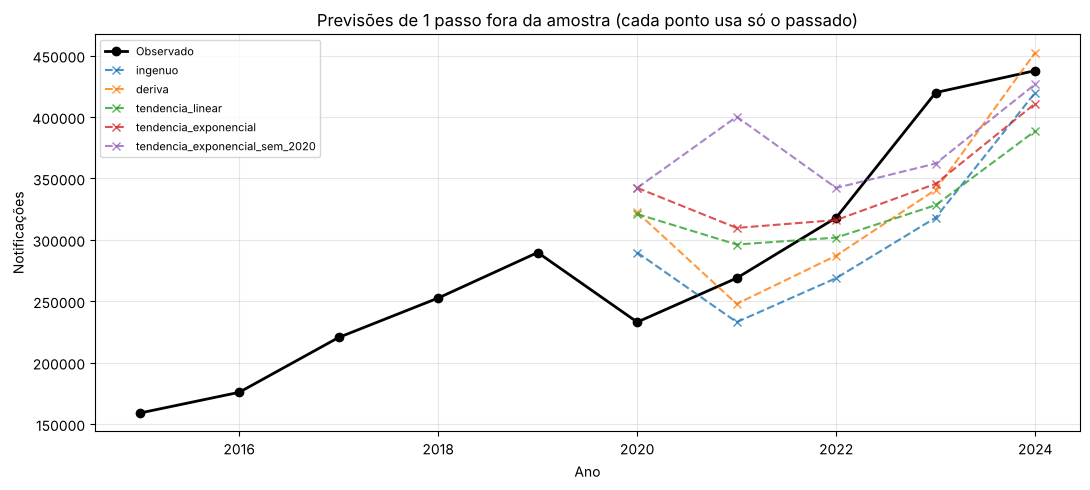

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df["ano"], df["frequencia"], "k-o", lw=2, label="Observado")
for nome, g in dobras.groupby("modelo", sort=False):
    ax.plot(g["ano_teste"], g["previsto"], "--", marker="x", label=nome, alpha=.8)
ax.set_title("Previsões de 1 passo fora da amostra (cada ponto usa só o passado)")
ax.set_xlabel("Ano"); ax.set_ylabel("Notificações"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Sensibilidade: sem o ano atípico de 2020
2020 teve queda de ~19,6%, e todos os modelos de tendência erram muito esse ano. Refazemos as métricas sem essa dobra **só para entender**; os critérios continuam valendo para o conjunto completo.

In [5]:
display(m.resumir_validacao(dobras, ignorar_anos=(m.ANO_ATIPICO,)))

,dobras,mae,rmse,mape_pct,mase,vies_pct,pior_ano_pct
modelo,,,,,,,
ingenuo,4,51189.000,59993.170,14.282,1.319,-14.282,24.247
deriva,4,36446.809,44361.154,9.934,0.935,-8.249,18.833
tendencia_linear,4,46085.641,54358.763,12.079,1.143,-6.994,21.820
tendencia_exponencial,4,35983.051,44472.516,9.908,0.906,-2.307,17.689
tendencia_exponencial_sem_2020,4,56103.627,72996.308,18.189,1.469,10.051,48.872


## 3. Decisão sobre o desempenho

In [6]:
indicador, _, _ = m.construir_indicador(caminho_relativo_csv="data-science/dados/brutos/sinan_feminino_2015_2024.csv")
v = indicador["modelo"]["validacao"]
print("Modelo selecionado (menor MAE entre os não-baseline):", indicador["modelo"]["selecionado"])
print("Critérios atendidos:", v["criterios_atendidos"])
print("Desempenho suficiente?", indicador["modelo"]["desempenho_suficiente"])

Modelo selecionado (menor MAE entre os não-baseline): deriva
Critérios atendidos: {'mase_menor_que_1': False, 'mape_dentro_do_limite': False, 'pior_ano_dentro_do_limite': False}
Desempenho suficiente? False


**Leitura:** nenhum modelo atende aos critérios. O melhor (*deriva*) erra em média ~15,6% (limite: 10%), com pior ano de 38%. Ele ganha pouco do ingênuo (MAE ~47 mil vs ~52 mil), diferença que, com 5 dobras, **não é estatisticamente distinguível de ruído**. Sem 2020 o erro cai (~9,9% de MAPE), mas isso é análise de sensibilidade, não resultado oficial.

**Conclusão: o desempenho é insuficiente para uso preditivo.** Por isso a projeção sai marcada com confiança *baixa* e com recomendação de **não exibir o valor numérico ao público**.

## 4. Projeção exploratória e intervalo

{'ano': 2025, 'valor': 468810, 'intervalo_80': [354234, 620446], 'intervalo_95': [282229, 778741], 'faixa_entre_modelos': [434172, 478125], 'confianca': 'baixa'}


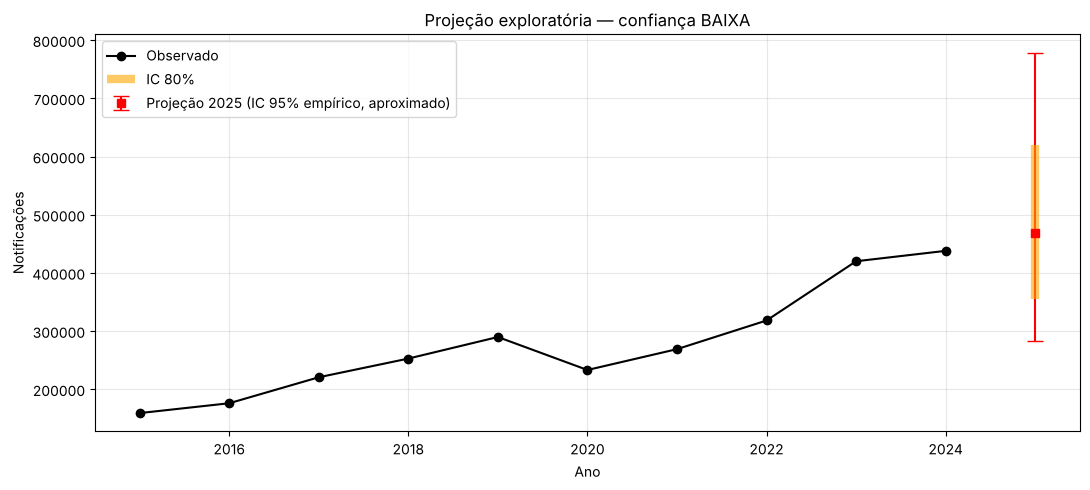

In [7]:
p = indicador["projecao_exploratoria"]
print({k: p[k] for k in ("ano", "valor", "intervalo_80", "intervalo_95", "faixa_entre_modelos", "confianca")})
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df["ano"], df["frequencia"], "k-o", label="Observado")
ax.errorbar([p["ano"]], [p["valor"]], yerr=[[p["valor"]-p["intervalo_95"][0]], [p["intervalo_95"][1]-p["valor"]]],
            fmt="rs", capsize=6, label="Projeção 2025 (IC 95% empírico, aproximado)")
ax.vlines(p["ano"], *p["intervalo_80"], color="orange", lw=6, alpha=.6, label="IC 80%")
ax.set_title("Projeção exploratória — confiança BAIXA"); ax.set_xlabel("Ano"); ax.set_ylabel("Notificações")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

O intervalo vem dos erros de validação (5 pontos), logo é **grosseiro**: lê-se como ordem de grandeza (de ~350 mil a ~620 mil no IC 80%), nunca como previsão pontual. Uma validação externa barata: quando o grupo extrair 2025 do TabNet (dado parcial, sujeito a revisão), comparar com esta projeção.

## 5. Indicador agregado (artefato para a API)
Arquivo: `data-science/saidas/indicador_notificacoes_agregado.json` (gerado por `python -m modelo.serie_sinan`).

In [8]:
print(json.dumps({k: indicador[k] for k in ("escopo", "indicadores_descritivos", "avisos")}, ensure_ascii=False, indent=2))

{
  "escopo": {
    "nivel": "agregado_nacional_anual",
    "unidade": "notificações registradas por ano",
    "nao_e": [
      "classificação de risco individual de mulheres",
      "estimativa da ocorrência real de violência (há subnotificação)",
      "dado sobre qualquer usuária do aplicativo"
    ],
    "uso_permitido": [
      "texto informativo de contexto sobre a tendência histórica das notificações",
      "material de apresentação acadêmica da etapa de Data Science"
    ],
    "exibir_apenas_em": "area_protegida"
  },
  "indicadores_descritivos": {
    "variacao_percentual_periodo": 175.4,
    "taxa_crescimento_anual_composta_pct": 11.9,
    "variacao_ultimo_ano_pct": 4.3,
    "ano_maior_queda": 2020,
    "variacao_ano_maior_queda_pct": -19.6
  },
  "avisos": [
    "Série com 10 pontos e uma variável: apenas indicador agregado exploratório; sem previsão confiável.",
    "Notificações não equivalem à ocorrência real de violência; mudanças de cobertura e de processo de notifica

## 6. Limitações e pendências (leia antes de usar)
1. **Série mínima:** 10 pontos, 1 variável, 5 dobras de teste. Qualquer conclusão estatística é frágil.
2. **Quebras estruturais:** 2020 (queda) e 2023 (+32%) não são explicáveis por tendência suave; **não verificamos as causas** (mudanças de cobertura/notificação, pandemia etc. são hipóteses, não achados).
3. **Notificação ≠ ocorrência:** subnotificação e mudanças no processo de notificação afetam a série.
4. **Conferência com a fonte pendente.** O CSV foi transcrito do TabNet e a conferência com o portal ainda consta como pendente (EDA da Entrega 2). Além disso, um estudo publicado na *Epidemiologia e Serviços de Saúde* (2025;34:e20240475) relata **~670 mil notificações em 2023** para mulheres no Brasil, enquanto o CSV traz **419.967**. A diferença não foi esclarecida (filtros, definição do ano, tipos de violência incluídos?). Não conseguimos abrir a tabela anual do artigo; a comparação usa o texto do resumo. **Até conferir, não exibir valores absolutos no app.**
5. **Sem recortes:** a base não tem UF, tipo de violência nem faixa etária. Um painel UF × ano (≈270 linhas) permitiria modelagem mais defensável.
6. **Não é risco individual.** Nenhuma saída deste notebook pode ser associada a uma usuária.